# Volatility Forecasting with GARCH

**Objective:** In this project, we study the GARCH model for volatility forecasting. We implement the model in Python, evaluate its out-of-sample forecasting performance using historical return data, and compare it with rolling historical volatility and EWMA benchmarks.

**Reference:** Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics, 31*(3), 307–327. [https://doi.org/10.1016/0304-4076(86)90063-1](https://doi.org/10.1016/0304-4076(86)90063-1).


**Table of Contents**

- 1. Mathematical Framework
  - 1.1. Setup
  - 1.2. The GARCH model
  - 1.3. Comparison with other models
- 2. Python Implementation
  - 2.1. Setup
  - 2.2. Historical data
  - 2.3. Model implementation
- 3. Backtesting
  - 3.1. Training
  - 3.2. Validation
  - 3.3. Final fit
  - 3.4. Testing
- 4. Discussion and Visualization



## 1. Mathematical Framework





### 1.1. Setup

**GARCH** stands for Generalized Autoregressive Conditional Heteroskedasticity. It models how the uncertainty of log returns changes over time. Financial returns often exhibit **volatility clustering**: large movements tend to be followed by large movements, and quiet periods by quiet periods. The standard Black–Scholes model assumes constant volatility, whereas GARCH allows conditional volatility to evolve over time. 

We discretize a time interval $[0,t]$, measured in years, into $n$ trading days, setting
$$
\Delta t = \frac{1}{252}, \qquad t_i = i\Delta t, \qquad 1\leq i\leq n.
$$

Let $S_{t_i}$ denote the adjusted price at observation time $t_i$. Define the log return by

$$
r_i=\ln\left(\frac{S_{t_i}}{S_{t_{i-1}}}\right).
$$

The objective of GARCH is to **forecast the conditional variance** of the next log return, based on the information available at the forecast date.

Let the $\sigma$-algebra $\mathcal F_{t_{i-1}}$ represent the information available through observation time $t_{i-1}$. We assume

$$
r_i=m\Delta t+\epsilon_i,\qquad \epsilon_i=\sqrt{h_i}\,Z_i,
$$

where the shocks $Z_i$ are independent and identically distributed, independent of $\mathcal F_{t_{i-1}}$, with mean $0$ and variance $1$. Then

$$
\mathbb E[r_i\mid\mathcal F_{t_{i-1}}]=m\Delta t,
\qquad
\operatorname{Var}(r_i\mid\mathcal F_{t_{i-1}})=h_i.
$$

- $m$: annualized constant mean log-return; $m\Delta t$ is the mean log return over one observation interval (one trading day).
- $\epsilon_i=r_i-m\Delta t$: the unexpected return shock.
- $h_i$: conditional variance per observation interval. We assume $h_i>0$ is $\mathcal F_{t_{i-1}}$-measurable—that is, determined by information available before observing $r_i$. The interval standard deviation is $\sqrt{h_i}$. Then today’s conditional volatility, in annualized units, is
$$
\sigma_i=\sqrt{h_i/\Delta t}. 
$$
- $Z_i$: standardized random shock. Two common choices for $Z_i$ are the standard normal distribution, $Z_i\sim\mathcal N(0,1)$, and a variance-one Student's $t$ distribution, a heavy-tailed extension.





### 1.2. The GARCH model

The standard Black–Scholes model assumes constant volatility, $\sigma_i=\sigma$. However, financial returns often exhibit volatility clustering: large price movements tend to be followed by large movements, and quiet periods by quiet periods. GARCH captures this behavior by updating the volatility forecast using past return shocks and previously observed data.

The **GARCH($p,q$)** model specifies

$$
h_i=\omega+\sum_{k=1}^{q}\alpha_k\epsilon_{i-k}^{2}
+\sum_{j=1}^{p}\beta_j h_{i-j}.
$$

- $\omega>0$ is the baseline variance contribution. 
- $\alpha_k$'s are shock-response coefficients, characterizing how strongly past squared return shocks $\epsilon_{i-k}^2$ affect current variance.
- $\beta_j$'s are variance-persistence coefficients, characterizing how strongly past conditional variances $h_{i-j}$ carry into current variance.
- We use Bollerslev's convention: $q$ counts squared-shock lags, and $p$ counts conditional-variance lags.
- With standardized shocks as above, the condition $\sum_{k=1}^{q}\alpha_k+\sum_{j=1}^{p}\beta_j<1$ gives a stationary long-run average daily variance $\bar h = \mathbb E[h_i]$

$$
\bar h=\frac{\omega}{1-\sum_{k=1}^{q}\alpha_k-\sum_{j=1}^{p}\beta_j}.
$$

The recurrence uses past return shocks and past conditional variances, starting from specified initial values. Its annualized volatility forecast is obtained from $\sigma_i=\sqrt{h_i/\Delta t}$.



In this project, we focus on $p=q=1$: one squared-shock lag and one conditional-variance lag. Writing $\alpha=\alpha_1$ and $\beta=\beta_1$, the general formula reduces to

$$
h_i=\omega+\alpha\epsilon_{i-1}^{2}+\beta h_{i-1}.
$$
and 
$$
r_i = m\Delta t + \sqrt{h_i} Z_i. 
$$

- $\omega>0$: baseline contribution to variance.
- $\alpha\ge0$: response to the most recent squared shock.
- $\beta\ge0$: persistence of the previous variance.
- When $\omega = \sigma^2\Delta t$, $m = \mu-\sigma^2/2$, $\alpha=\beta=0$, and $Z_i\sim\mathcal N(0,1)$, the GARCH(1,1) model reduces to the Black-Scholes model.

Because shocks are squared, positive and negative shocks of equal size have the same effect in this symmetric model.

Assuming $\alpha+\beta<1$, the stationary model has finite unconditional variance

$$
\bar h=\frac{\omega}{1-\alpha-\beta}.
$$

Equivalently,

$$
h_i-\bar h=\alpha(\epsilon_{i-1}^{2}-\bar h)+\beta(h_{i-1}-\bar h).
$$

The sum $\alpha+\beta$ governs persistence in expected future variance: values closer to $1$ imply slower reversion toward $\bar h$.



### 1.3. Comparison with other models

For the discrete models, $h_{i+1\mid i}$ denotes the next-day variance forecast using observations through $t_i$. Its annualized volatility is $\sqrt{h_{i+1\mid i}/\Delta t}$.

**GBM / Black–Scholes.** When $\omega=\sigma^2\Delta t$, $m=\mu-\sigma^2/2$, $\alpha=\beta=0$, and the shocks are independent standard normals, GARCH(1,1) matches the exact sampled GBM log returns:

$$
r_i=\left(\mu-\frac{\sigma^2}{2}\right)\Delta t
+\sigma\sqrt{\Delta t}\,Z_i.
$$

The variance is constant. Black–Scholes option pricing additionally requires risk-neutral dynamics and the usual market assumptions.


**Rolling historical volatility.** Using a window of $L>1$ daily returns, define

$$
\bar r_{i,L}=\frac1L\sum_{j=i-L+1}^{i}r_j,
\qquad
\widehat h_{i+1\mid i}^{\mathrm{roll}} = \operatorname{Var}_{\mathrm{sample}}(r_i,r_{i-1},\cdots,r_{i-L+1})
=\frac1{L-1}\sum_{j=i-L+1}^{i}(r_j-\bar r_{i,L})^2.
$$

This uses the most recent sample variance as tomorrow's forecast. Observations receive equal weight within the window and zero weight outside it. The forecast can change abruptly when an old observation leaves the window. The window length $L$ must be chosen without using test outcomes.

**EWMA.** Exponentially weighted moving average variance satisfies

$$
h_{i+1\mid i}=\lambda h_i+(1-\lambda)\epsilon_i^2,
\qquad 0<\lambda<1.
$$

Past squared shocks receive geometrically declining weights. Smaller $\lambda$ gives more weight to the latest shock. EWMA is the boundary case of GARCH(1,1), where $\omega=0$, $\alpha=1-\lambda$, $\beta=\lambda$. Unlike stationary GARCH, it has no fixed long-run variance target; future variance forecasts remain flat under this specification.

**Heston.** Writing $\sigma_i=\sqrt{h_i/\Delta t}$, the GARCH(1,1) update is
$$
\sigma_{i+1}^2 = \frac{\omega}{\Delta t} + \alpha\sigma_i^2Z_i^2 + \beta\sigma_i^2, 
$$
whereas the discrete Heston model updates by
$$
\sigma_{i+1}^2 = \left(\sigma_i^2 + \kappa(\theta-\sigma_i^2)\Delta t + \xi\sigma_i\sqrt{\Delta t}Z_i^v\right)^+
$$

The main difference is how shocks enter the variance update. GARCH uses the squared return shock $Z_i^2$, which can be recovered from observed returns given the parameters and initialized variance. Heston uses a separate variance shock $Z_i^v$, correlated with the stock-return shock. Consequently, Heston’s variance is generally a latent state rather than a deterministic function of past returns.


## 2. Python Implementation

We use SPY, an ETF tracking the S&P 500, for backtesting. 

### 2.1. Setup


We use daily log returns expressed as decimals. The models forecast daily conditional variance $h_i$. For reporting, we convert this to annualized volatility using $\sigma_i=\sqrt{h_i/\Delta t}$, where $\Delta t=1/252$.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from scipy.optimize import minimize
from scipy import stats
from scipy.special import gammaln

import warnings
# to get rid of the warnings when downloading data from yfinance
if hasattr(pd.errors, "Pandas4Warning"):
    warnings.filterwarnings(
        "ignore",
        category=pd.errors.Pandas4Warning,
        module=r"yfinance\..*",
    )

# fixing the random seed so that random simulations are reproducible
# 42 is a reference to Douglas Adams’s The Hitchhiker’s Guide to the Galaxy
rng = np.random.default_rng(42)

# time measured in years; one trading year contains 252 trading days
TRADING_DAYS = 252
dt = 1 / TRADING_DAYS


### 2.2. Historical data

We download **SPY adjusted daily closing prices** and compute log returns in decimal units:

$$
r_i=\ln\left(\frac{S_{t_i}}{S_{t_{i-1}}}\right).
$$

- **Training:** 2010–2015, for initial parameter estimation.
- **Validation:** 2016–2018, for selecting the rolling window $L$ and EWMA decay $\lambda$.
- **Test:** 2019–2025, for final out-of-sample evaluation.

After selecting settings, we refit using training and validation data together before testing. Settings remain fixed during testing; each forecast uses only information available at its forecast date.

Prices are adjusted for splits and dividends. We include December 2009 to calculate the first return of 2010. Missing returns are omitted without filling prices.


In [21]:
# Download adjusted prices (the end date is exclusive).
raw = yf.download(
    "SPY", start="2009-12-01", end="2026-01-01",
    auto_adjust=True, # Prices are adjusted for splits and dividends. 
    multi_level_index=False, progress=False,
)

display(raw.head(), raw.tail())


,Close,High,Low,Open,Volume
Date,,,,,
2009-12-01,82.414032,82.680601,81.991966,82.132651,159613700
2009-12-02,82.377022,82.939779,82.132666,82.399235,132315100
2009-12-03,81.732796,83.065639,81.666156,82.599147,167324900
2009-12-04,82.199295,83.213732,81.481041,82.813879,274907800
2009-12-07,82.073433,82.584357,81.814270,82.125271,127973800


,Close,High,Low,Open,Volume
Date,,,,,
2025-12-24,685.029480,685.476005,682.469458,682.618320,39445600
2025-12-26,684.959961,686.299474,683.928043,685.287420,41613300
2025-12-29,682.519043,683.858617,680.752870,682.211448,62559500
2025-12-30,681.685608,683.223583,681.258948,682.122200,47160700
2025-12-31,676.635010,682.032851,676.426676,681.814586,74144800


In [22]:
# use adjusted closing prices
prices = raw["Close"]

# Compute daily log returns.
returns = np.log(prices / prices.shift(1))

# create a DataFrame
data = pd.DataFrame({"adjusted_close": prices, "log_return": returns})
data = data.loc["2010":"2025"].dropna()

# Split chronologically, without shuffling.
train = data.loc["2010":"2015"].copy()
validation = data.loc["2016":"2018"].copy()
test = data.loc["2019":"2025"].copy()

print(f"Training: {len(train)}; validation: {len(validation)}; test: {len(test)} observations")

display(data.head(), data.tail())


Training: 1510; validation: 754; test: 1760 observations


,adjusted_close,log_return
Date,,
2010-01-04,84.368950,0.016817
2010-01-05,84.592323,0.002644
2010-01-06,84.651855,0.000704
2010-01-07,85.009232,0.004213
2010-01-08,85.292099,0.003322


,adjusted_close,log_return
Date,,
2025-12-24,685.029480,0.003511
2025-12-26,684.959961,-0.000101
2025-12-29,682.519043,-0.003570
2025-12-30,681.685608,-0.001222
2025-12-31,676.635010,-0.007437


### 2.3. Model implementation

We define reusable functions for three volatility models:

- **Rolling variance:** calculate the sample variance of the latest $L$ returns.
- **EWMA:** update the variance forecast using the latest squared return shock and a decay factor $\lambda$.
- **GARCH(1,1):** compute the variance recursion and forecast the next day's variance using given parameters. Parameter estimation is covered in Section 3.1.

All forecasts are **daily variances** $h$ in squared decimal-return units. Annualized volatility is $\sqrt{h/\Delta t}$.

We separate model functions from the backtesting loop. Each forecast uses only observations available at its forecast date. We implement rolling variance first, then EWMA, and finally GARCH.


**Rolling variance**

The function takes a pandas Series of daily log returns and an integer window length $L>1$. It returns daily variance forecasts indexed by the day being predicted. For each day, we explicitly calculate the mean and sample variance of the preceding $L$ returns; the first $L$ forecasts are unavailable (`NaN`). The update uses the formula
$$
\widehat h_{i+1\mid i}^{\mathrm{roll}} = \frac1{L-1}\sum_{j=i-L+1}^{i}(r_j-\bar r_{i,L})^2.
$$
We arrange overlapping windows as rows of a NumPy view and compute their means and sample variances together. This removes the Python loop while keeping the formula explicit. The last input return is excluded because its next-day forecast falls beyond the input dates.


In [23]:
def rolling_variance(returns, L):
    """Forecast daily variance; assumes 1 < L < len(returns)."""

    # we can call the built-in function as follows
    # return returns.rolling(window=L).var(ddof=1).shift(1)
    # but we use our own code to explicitly demonstrate the computing process

    r = returns.to_numpy()
    h = np.full(len(r), np.nan)

    # Each row contains L past returns for one forecast date.
    windows = np.lib.stride_tricks.sliding_window_view(r[:-1], L)
    means = np.sum(windows, axis=1, keepdims=True) / L
    h[L:] = np.sum((windows - means) ** 2, axis=1) / (L - 1)

    return pd.Series(h, index=returns.index)


**EWMA**

We update the daily variance forecast by

$$
h_{i+1\mid i}=\lambda h_{i\mid i-1}+(1-\lambda)(r_i-m\Delta t)^2.
$$

- `lam`: decay factor $0<\lambda<1$; larger values give more weight to the previous forecast.
- `h0`: starting daily variance, known before the first input return.
- `mean`: daily mean log return $m\Delta t$; the default is zero. Any estimated mean and starting variance must use only earlier data.

The input is a nonempty Series of daily returns without missing values. As with rolling variance, forecasts are indexed by the day being predicted.

We compute squared shocks with NumPy and initialize the first forecast with `h0`. A loop then applies the recursion, using only the preceding shock and variance forecast. This requires $O(n)$ operations for $n$ returns.


In [24]:
def ewma_variance(returns, lam, h0, mean=0.0):
    """Forecast daily variance using prior shocks and starting variance h0."""

    # we can use the built-in .ewm method
    # but for explicit demonstration we use the following code

    squared_shocks = (returns.to_numpy() - mean) ** 2
    h = np.full(len(returns), np.nan)
    h[0] = h0

    for i in range(1, len(returns)):
        h[i] = lam * h[i - 1] + (1 - lam) * squared_shocks[i - 1]

    return pd.Series(h, index=returns.index)


**GARCH(1,1)**

The daily conditional variance follows

$$
h_{i+1\mid i}=\omega+\alpha(r_i-m\Delta t)^2+\beta h_{i\mid i-1}.
$$

`garch_variance` computes this recursion. Here, `mean` is the daily mean log return $m\Delta t$, and `h0` is the initial variance. Inputs are nonempty returns without missing values. Out-of-sample forecasts use parameters and initial variance determined from earlier data only.


In [25]:
def garch_variance(returns, omega, alpha, beta, h0, mean=0.0):
    """Forecast daily variance using the GARCH(1,1) recursion."""

    # there is an established package, arch, for GARCH implementation
    # but for explicit demonstration we use our own code
    
    squared_shocks = (returns.to_numpy() - mean) ** 2
    h = np.full(len(returns), np.nan)
    h[0] = h0

    for i in range(1, len(returns)):
        h[i] = omega + alpha * squared_shocks[i - 1] + beta * h[i - 1]

    return pd.Series(h, index=returns.index)


The function `garch_variance` is shared by **Gaussian GARCH(1,1)** and **Student's $t$ GARCH(1,1)**.


## 3. Backtesting

The historical data is separated into three parts. We use **training data** to fit model parameters, **validation data** to choose settings based on subsequent forecast performance, and **test data** for the final evaluation. 

| Stage | Rolling variance | EWMA | Gaussian GARCH / Student's t GARCH |
|---|---|---|---|
| **Training: 2010–2015** | No fixed coefficients to estimate; specify candidate windows $L$. | Estimate the daily mean $m\Delta t$ and initialize $h_0$; specify candidate decay factors $\lambda$. | Use the same estimated daily mean; initialize $h_0$ and estimate $\omega,\alpha,\beta$ (and also $\nu$ for Student's $t$ distribution) by minimizing the negative log-likelihood. |
| **Validation: 2016–2018** | Select $L$ by average validation QLIKE. | Select $\lambda$ by average validation QLIKE; keep the mean fixed. | Evaluate forecasts with fitted coefficients and mean fixed; no additional parameters are selected. |
| **Final fit: 2010–2018** | Keep the validation-selected $L$ fixed; no coefficients to refit. | Re-estimate the daily mean $m\Delta t$ and initial variance $h_0$ using training and validation data; keep $\lambda$ fixed. | Use the updated mean and $h_0$; re-estimate $\omega,\alpha,\beta$ separately for each model, and $\nu$ for Student's $t$ GARCH. |
| **Test: 2019–2025** | Keep selected $L$ fixed. | Keep selected $\lambda$ and the final fitted mean fixed. | Keep final fitted $\omega,\alpha,\beta$ and mean fixed. |



### 3.1. Training

**Training Gaussian GARCH(1,1)**


We use **2010–2015 only** to estimate the common daily mean and initialize variance. We also specify candidates for validation: 
$$
L\in\{20,60,126,252\}, \qquad \text{ and } \qquad \lambda\in\{0.90,0.94,0.97,0.99\}. 
$$

For Gaussian GARCH(1,1), hold the daily mean fixed and estimate $\omega,\alpha,\beta$ by minimizing the Gaussian negative log-likelihood, with $h_i=h_{i\mid i-1}$:

$$
-\ell=\frac12\sum_{i=1}^{n}\left[\ln(2\pi)+\ln h_i+\frac{(r_i-m\Delta t)^2}{h_i}\right].
$$

We require $\omega>0$, $\alpha,\beta\geq0$, and $\alpha+\beta<1$. The initial variance is the training sample variance.

In [26]:
def garch_nll(params, returns, h0, mean):
    """Gaussian negative log-likelihood with fixed mean and initial variance."""
    
    omega, alpha, beta = params
    h = garch_variance(returns, omega, alpha, beta, h0, mean).to_numpy()
    squared_shocks = (returns.to_numpy() - mean) ** 2
    return 0.5 * np.sum(np.log(2 * np.pi) + np.log(h) + squared_shocks / h)


In [27]:
# Training data only: common daily mean and initial variance.
train_returns = train["log_return"]
train_mean = train_returns.mean()
train_h0 = train_returns.var(ddof=1)

L_candidates = [20, 60, 126, 252]
lam_candidates = [0.90, 0.94, 0.97, 0.99]

# Scale and fit in percentage-return units for numerical stability.
scaled_returns = 100 * train_returns
scaled_mean = 100 * train_mean
scaled_h0 = 100**2 * train_h0

result = minimize(
    garch_nll,
    x0=[0.05 * scaled_h0, 0.05, 0.90], # initial guess
    args=(scaled_returns, scaled_h0, scaled_mean),
    method="SLSQP", # Sequential Least Squares Programming
    bounds=[(1e-10, None), (0, 1), (0, 1)],
    constraints={"type": "ineq", "fun": lambda p: 1 - 1e-6 - p[1] - p[2]},
    options={"maxiter": 1000, "ftol": 1e-8}, # maximum iterations: 1000; tolerance: 1e-8
)

omega, alpha, beta = result.x
# scale back omega
omega = omega / 100**2

training_parameters = pd.Series({
    "daily mean": train_mean, "initial variance": train_h0,
    "omega": omega, "alpha": alpha, "beta": beta,
    "alpha + beta": alpha + beta,
})
print(f"Training: {train_returns.index.min().date()} to {train_returns.index.max().date()}")
print(f"Observations: {len(train_returns)}; optimizer converged: {result.success}")
display(training_parameters.to_frame("estimate"))


Training: 2010-01-04 to 2015-12-31
Observations: 1510; optimizer converged: True


,estimate
daily mean,0.000481
initial variance,0.000099
omega,0.000004
alpha,0.139911
beta,0.819830
alpha + beta,0.959741


**Training Student's $t$ GARCH(1,1)**

Let $T_i\sim t_\nu$ with $\nu>2$, and set $Z_i=\sqrt{(\nu-2)/\nu}\,T_i$ so that $\operatorname{Var}(Z_i)=1$. The variance recursion is unchanged. With $\epsilon_i=r_i-\widehat m\Delta t$, the negative log-likelihood is

$$
-\ell_t=\sum_{i=1}^{n}\left[
\log\Gamma\!\left(\frac{\nu}{2}\right)
-\log\Gamma\!\left(\frac{\nu+1}{2}\right)
+\frac12\log\!\left(\pi(\nu-2)h_i\right)
+\frac{\nu+1}{2}\log\!\left(1+\frac{\epsilon_i^2}{(\nu-2)h_i}\right)
\right],
$$

where $\Gamma$ is the gamma function. We compute the log-density directly: `gammaln` evaluates $\log\Gamma$, and `np.log1p(x)` computes $\log(1+x)$ accurately even when $x$ is close to zero.

Using **2010–2015 only**, estimate $\omega,\alpha,\beta,\nu$, with the same fixed daily mean, initial variance, and percentage-return scaling as the Gaussian fit. Require $\omega>0$, $\alpha,\beta\geq0$, $\alpha+\beta<1$, and $\nu>2$. Only $\omega$ needs conversion back to decimal-return variance units.


In [28]:
def garch_t_nll(params, returns, h0, mean):
    """Negative log-likelihood for variance-one Student's t shocks."""
    
    omega, alpha, beta, nu = params
    h = garch_variance(returns, omega, alpha, beta, h0, mean).to_numpy()
    squared_shocks = (returns.to_numpy() - mean) ** 2
    constant = gammaln(nu / 2) - gammaln((nu + 1) / 2)
    return np.sum(
        constant + 0.5 * np.log(np.pi * (nu - 2) * h)
        + 0.5 * (nu + 1) * np.log1p(squared_shocks / ((nu - 2) * h))
    )


In [29]:
# Fit Student's t GARCH using the same training data and fixed mean.
t_result = minimize(
    garch_t_nll,
    x0=[0.05 * scaled_h0, 0.05, 0.90, 8.0],
    args=(scaled_returns, scaled_h0, scaled_mean),
    method="SLSQP",
    bounds=[(1e-10, None), (0, 1), (0, 1), (2 + 1e-6, None)],
    constraints={"type": "ineq", "fun": lambda p: 1 - 1e-6 - p[1] - p[2]},
    options={"maxiter": 1000, "ftol": 1e-8},
)
omega_t, alpha_t, beta_t, nu_t = t_result.x
omega_t = omega_t / 100**2

training_t_parameters = pd.Series({
    "daily mean": train_mean, "initial variance": train_h0,
    "omega": omega_t, "alpha": alpha_t, "beta": beta_t,
    "alpha + beta": alpha_t + beta_t, "nu": nu_t,
})

print(f"Training observations: {len(train_returns)}; optimizer converged: {t_result.success}")
display(training_t_parameters.to_frame("Student's t estimate"))


Training observations: 1510; optimizer converged: True


,Student's t estimate
daily mean,0.000481
initial variance,0.000099
omega,0.000004
alpha,0.145290
beta,0.822358
alpha + beta,0.967648
nu,6.039393


### 3.2. Validation

We use **2016–2018** to select $L$ and $\lambda$. The training mean and GARCH coefficients remain fixed. We run each model through training and validation in order, preserving its history, but only validation data is used to select $L$ and $\lambda$. 

We also evaluate **Student's $t$ GARCH(1,1)** using its fixed training estimates. No additional settings are selected: $\nu$ was estimated during training, and variance forecasts reuse `garch_variance` with the fitted $\omega_t,\alpha_t,\beta_t$. Both GARCH models use the same validation dates and variance proxy.

True daily variance is unobserved. We use 
$$
v_i=(r_i-\widehat m\Delta t)^2
$$
as a noisy proxy, with the same training-estimated mean for every model. This proxy also reflects any error in that mean estimate.

For $N$ validation observations and forecasts $\widehat h_i$, compute the quasi-likelihood loss
$$
\mathrm{QLIKE}=\frac1N\sum_i\left(\ln\widehat h_i+\frac{v_i}{\widehat h_i}\right). 
$$
- $\ln(\widehat h_i)$ discourages excessively large forecasts.
- $v_i/\widehat h_i$ penalizes forecasts that are too small relative to the observed shock.
- The QLIKE loss function can be negative; the lower QLIKE is, the better the estimate is.
- Gaussian negative log-likelihood and QLIKE are equivalent loss functions, since
$$
-\ell
=\frac12\sum_{i=1}^{N}
\left[\ln(2\pi)+\ln h_i+\frac{v_i}{h_i}\right]
=\frac N2\ln(2\pi)+\frac N2\,\mathrm{QLIKE}.
$$

Another possible measure of performance is the mean squared error:
$$
\mathrm{MSE}=\frac1N\sum_i(v_i-\widehat h_i)^2.
$$
In this project **we use QLIKE as the primary performance measure** and MSE as a secondary measure.



In [30]:
def forecast_scores(forecast, proxy):
    """Compare positive variance forecasts and squared shocks on matching dates."""
    
    return {
        "QLIKE": (np.log(forecast) + proxy / forecast).mean(),
        "MSE": ((proxy - forecast) ** 2).mean(),
    }


In [31]:
# Include training history so forecasts are ready on the first validation day.
history = pd.concat([train["log_return"], validation["log_return"]])
validation_dates = validation.index
variance_proxy = (validation["log_return"] - train_mean) ** 2

validation_forecasts = {}
for L in L_candidates:
    validation_forecasts[f"Rolling L={L}"] = rolling_variance(history, L).loc[validation_dates]

for lam in lam_candidates:
    validation_forecasts[f"EWMA lam={lam:.2f}"] = ewma_variance(
        history, lam, train_h0, train_mean
    ).loc[validation_dates]

validation_forecasts["Gaussian GARCH"] = garch_variance(
    history, omega, alpha, beta, train_h0, train_mean
).loc[validation_dates]

validation_forecasts["Student's t GARCH"] = garch_variance(
    history, omega_t, alpha_t, beta_t, train_h0, train_mean
).loc[validation_dates]

validation_forecasts = pd.DataFrame(validation_forecasts)
validation_scores = pd.DataFrame({
    name: forecast_scores(validation_forecasts[name], variance_proxy)
    for name in validation_forecasts.columns
}).T

best_L = min(L_candidates, key=lambda L: validation_scores.loc[f"Rolling L={L}", "QLIKE"])
best_lam = min(lam_candidates, key=lambda lam: validation_scores.loc[f"EWMA lam={lam:.2f}", "QLIKE"])

print(f"Validation observations: {len(validation_dates)}")
print(f"Selected by QLIKE: L={best_L}, lam={best_lam}")
display(validation_scores.sort_values("QLIKE"))


Validation observations: 754
Selected by QLIKE: L=60, lam=0.94


,QLIKE,MSE
Gaussian GARCH,-8.951057,2.855260e-08
Student's t GARCH,-8.950063,2.862648e-08
EWMA lam=0.94,-8.865295,2.896273e-08
EWMA lam=0.97,-8.849264,2.968374e-08
EWMA lam=0.90,-8.833820,2.879031e-08
Rolling L=60,-8.761284,3.056993e-08
EWMA lam=0.99,-8.731044,3.111768e-08
Rolling L=20,-8.724103,2.999405e-08
Rolling L=126,-8.654369,3.175221e-08
Rolling L=252,-8.609536,3.195131e-08


### 3.3. Final fit

**Final fit for Gaussian GARCH(1,1)**

We keep the validation-selected $L$ and $\lambda$ fixed. Before testing, we refit the common daily mean and GARCH coefficients using **2010–2018**. 

We then evaluate forecasts on **2019–2025**, using QLIKE as the primary measure and MSE as a secondary measure. Parameters stay fixed throughout testing, while variance forecasts update daily using earlier returns. All models use the same dates and squared-shock proxy. 


In [32]:
# Final fit uses training and validation returns only.
pretest_returns = pd.concat([train["log_return"], validation["log_return"]])
final_mean = pretest_returns.mean()
final_h0 = pretest_returns.var(ddof=1)

final_fit = minimize(
    garch_nll,
    x0=[0.05 * 100**2 * final_h0, 0.05, 0.90],
    args=(100 * pretest_returns, 100**2 * final_h0, 100 * final_mean),
    method="SLSQP",
    bounds=[(1e-10, None), (0, 1), (0, 1)],
    constraints={"type": "ineq", "fun": lambda p: 1 - 1e-6 - p[1] - p[2]},
    options={"maxiter": 1000, "ftol": 1e-8},
)
final_omega, final_alpha, final_beta = final_fit.x
final_omega = final_omega / 100**2

final_parameters = pd.Series({
    "daily mean": final_mean, "initial variance": final_h0,
    "omega": final_omega, "alpha": final_alpha, "beta": final_beta,
    "alpha + beta": final_alpha + final_beta,
})
print(f"Final fit observations: {len(pretest_returns)}; optimizer converged: {final_fit.success}")
print(f"Fixed settings: L={best_L}, lam={best_lam}")
display(final_parameters.to_frame("estimate"))


Final fit observations: 2264; optimizer converged: True
Fixed settings: L=60, lam=0.94


,estimate
daily mean,0.000437
initial variance,0.000089
omega,0.000003
alpha,0.159356
beta,0.804773
alpha + beta,0.964129


**Final fit for Student's $t$ GARCH(1,1)**

Refit $\omega,\alpha,\beta,\nu$ on **2010–2018**, using the same fixed daily mean and initial variance as the Gaussian refit. These estimates are separate from the Gaussian coefficients and remain fixed during testing. The parameter $\nu$ enters the likelihood, but only $\omega,\alpha,\beta$ enter the variance recursion.


In [33]:
# Refit Student's t GARCH on training and validation returns only.
final_t_fit = minimize(
    garch_t_nll,
    x0=[0.05 * 100**2 * final_h0, 0.05, 0.90, 8.0],
    args=(100 * pretest_returns, 100**2 * final_h0, 100 * final_mean),
    method="SLSQP",
    bounds=[(1e-10, None), (0, 1), (0, 1), (2 + 1e-6, None)],
    constraints={"type": "ineq", "fun": lambda p: 1 - 1e-6 - p[1] - p[2]},
    options={"maxiter": 1000, "ftol": 1e-8},
)
final_omega_t, final_alpha_t, final_beta_t, final_nu_t = final_t_fit.x
final_omega_t = final_omega_t / 100**2

final_t_parameters = pd.Series({
    "daily mean": final_mean, "initial variance": final_h0,
    "omega": final_omega_t, "alpha": final_alpha_t, "beta": final_beta_t,
    "alpha + beta": final_alpha_t + final_beta_t, "nu": final_nu_t,
})
print(f"Final fit observations: {len(pretest_returns)}; optimizer converged: {final_t_fit.success}")
display(final_t_parameters.to_frame("Student's t estimate"))


Final fit observations: 2264; optimizer converged: True


,Student's t estimate
daily mean,0.000437
initial variance,0.000089
omega,0.000002
alpha,0.164876
beta,0.828353
alpha + beta,0.993229
nu,4.944709


### 3.4. Testing

Evaluate rolling variance, EWMA, Gaussian GARCH(1,1), and Student's $t$ GARCH(1,1) on **2019–2025** using the same squared-shock proxy and test dates. Both GARCH models use their own final-fit coefficients from Section 3.3. Parameters remain fixed; each daily forecast uses only earlier returns. The fitted $\nu$ affects Student's $t$ parameter estimation but does not enter the variance recursion directly.


In [34]:
# Run through earlier history; score only test dates.
full_history = pd.concat([pretest_returns, test["log_return"]])
test_dates = test.index
test_proxy = (test["log_return"] - final_mean) ** 2

test_forecasts = pd.DataFrame({
    "Rolling": rolling_variance(full_history, best_L),
    "EWMA": ewma_variance(full_history, best_lam, final_h0, final_mean),
    "Gaussian GARCH": garch_variance(
        full_history, final_omega, final_alpha, final_beta, final_h0, final_mean
    ),
    "Student's t GARCH": garch_variance(
        full_history, final_omega_t, final_alpha_t, final_beta_t, final_h0, final_mean
    ),
}).loc[test_dates]

test_scores = pd.DataFrame({
    name: forecast_scores(test_forecasts[name], test_proxy)
    for name in test_forecasts.columns
}).T

print(f"Test period: {test_dates.min().date()} to {test_dates.max().date()}")
print(f"Test observations: {len(test_dates)}")
display(test_scores.sort_values("QLIKE"))


Test period: 2019-01-02 to 2025-12-31
Test observations: 1760


,QLIKE,MSE
Gaussian GARCH,-8.259572,2.849544e-07
Student's t GARCH,-8.256195,2.906149e-07
EWMA,-8.193821,3.276058e-07
Rolling,-8.054142,3.893375e-07


## 4. Discussion and Visualization

In view of the results from the previous section, both the QLIKE and MSE measurements indicate that Gaussian GARCH(1,1) outperforms EWMA and Rolling in volatility forecasting. 


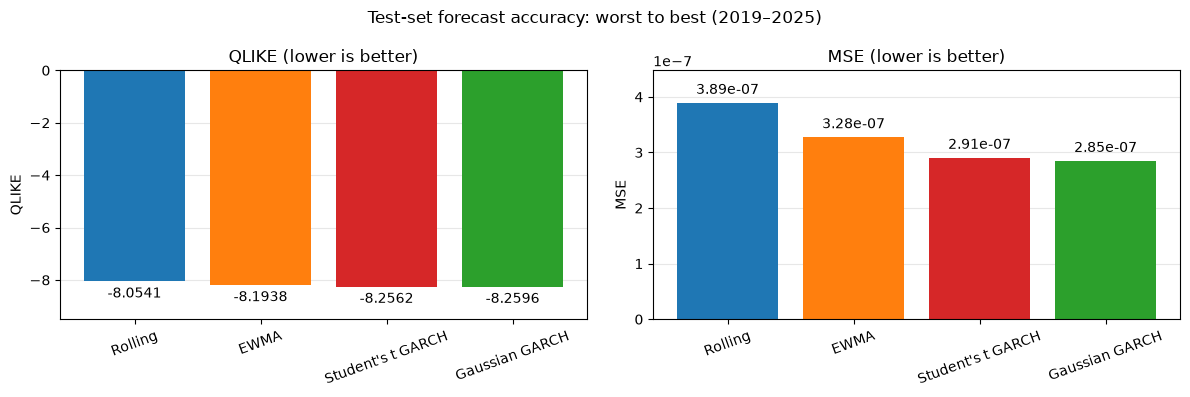

In [35]:
# Compare test-set scores; lower values are better for both measures.
scores = test_scores.loc[["Rolling", "EWMA", "Gaussian GARCH", "Student's t GARCH"]]
colors = dict(zip(scores.index, ["C0", "C1", "C2", "C3"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric, label_format in zip(axes, ["QLIKE", "MSE"], ["%.4f", "%.2e"]):
    ranked = scores.sort_values(metric, ascending=False)
    bars = ax.bar(ranked.index, ranked[metric],
                  color=[colors[model] for model in ranked.index])
    ax.bar_label(bars, fmt=label_format, padding=4)
    ax.set_title(f"{metric} (lower is better)")
    ax.tick_params(axis="x", labelrotation=20)
    ax.set_ylabel(metric)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.margins(y=0.15)

axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
fig.suptitle("Test-set forecast accuracy: worst to best (2019–2025)")
plt.tight_layout()
plt.show()



It is difficult to compare the forecasted volatility with the real volatility, as **the real volatility is not observable**. But for visualization, we can first take a look at the SPY stock price and log returns to get a feel for real volatility. 

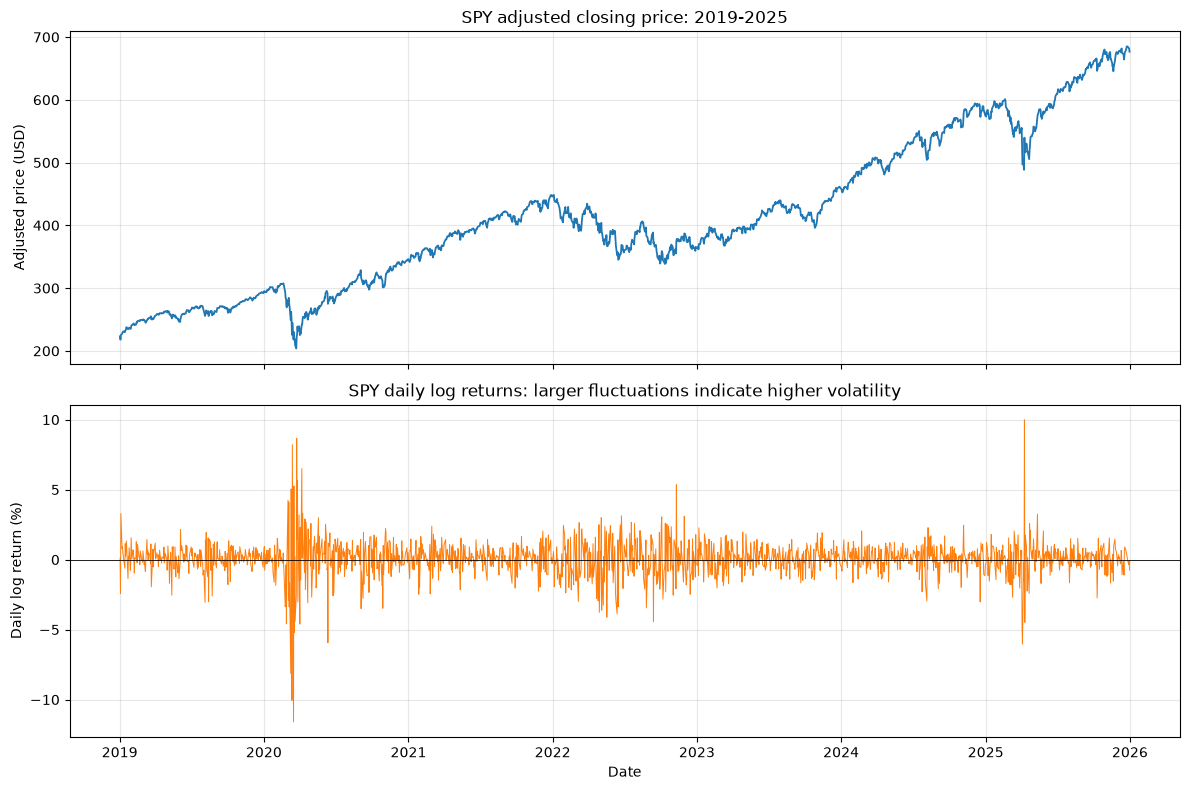

In [36]:
# Observed SPY prices and returns over the same test period.
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(test.index, test["adjusted_close"], color="C0", linewidth=1.3)
axes[0].set_title("SPY adjusted closing price: 2019-2025")
axes[0].set_ylabel("Adjusted price (USD)")

axes[1].plot(test.index, 100 * test["log_return"], color="C1", linewidth=0.7)
axes[1].axhline(0, color="black", linewidth=0.6)
axes[1].set_title("SPY daily log returns: larger fluctuations indicate higher volatility")
axes[1].set_ylabel("Daily log return (%)")
axes[1].set_xlabel("Date")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


To visualize the forecasts given by the four models, we plot their volatility forecasts together over the test period. We also take a closer look at their responses to the early 2020 market shock, triggered by the COVID-19 pandemic. 

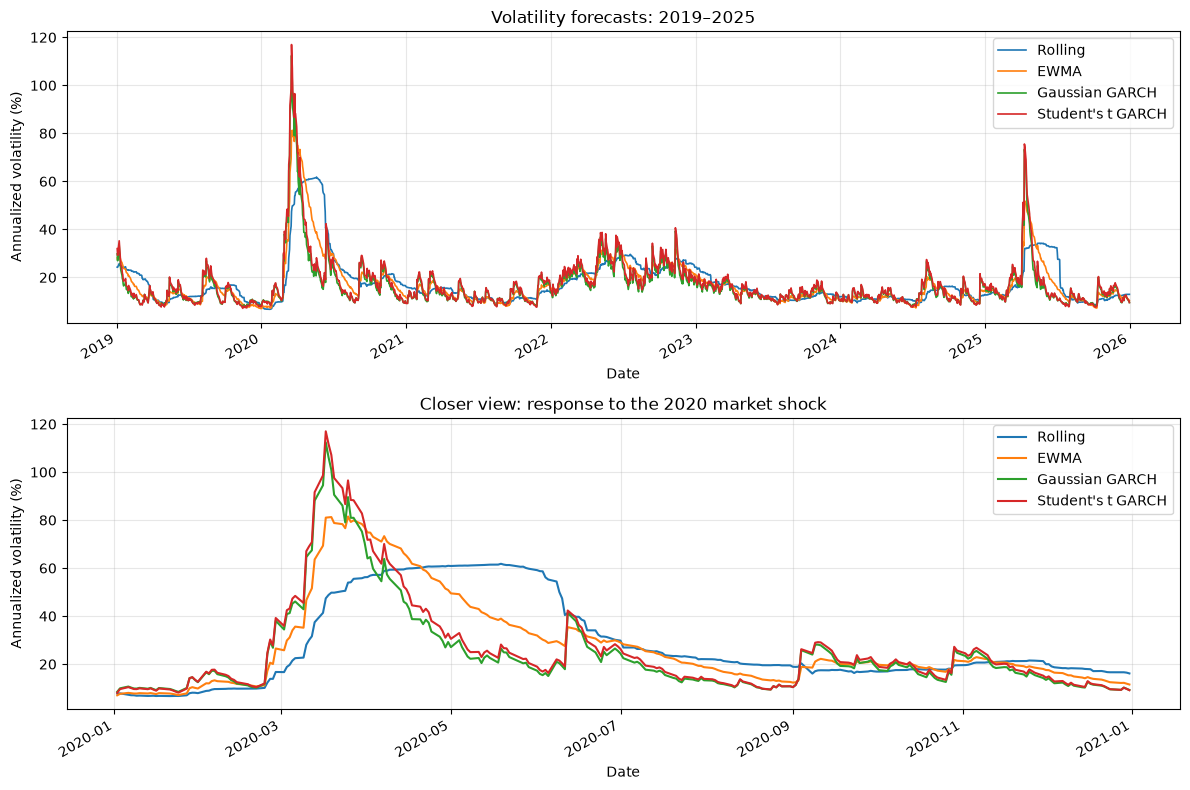

In [37]:
# Convert daily variance forecasts to annualized volatility (%).
volatility = 100 * np.sqrt(test_forecasts / dt)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

volatility.plot(ax=axes[0], linewidth=1.2)
axes[0].set_title("Volatility forecasts: 2019–2025")

volatility.loc["2020"].plot(ax=axes[1], linewidth=1.5)
axes[1].set_title("Closer view: response to the 2020 market shock")

for ax in axes:
    ax.set_ylabel("Annualized volatility (%)")
    ax.set_xlabel("Date")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


The charts suggest that the Gaussian GARCH(1,1) model better captures market volatility. 

**Forecasts versus observed squared shocks**

Since the real volatility is not observable, we use observed squared shocks as a proxy
$$
v_i=(r_i-\widehat m\Delta t)^2,
\qquad
r_i=\ln\left(\frac{S_{t_i}}{S_{t_{i-1}}}\right)
$$
for comparison. Moreover, to reduce daily noise, we perform a weekly average, namely, 
$$
\overline v_w=\frac{1}{N_w}\sum_{i\in w}(r_i-\widehat m\Delta t)^2,
$$
where $N_w$ is the number of observed trading days in that week. We also average the forecasted variances in the same manner. 

We then plot and compare the forecasted variances with the proxy. 


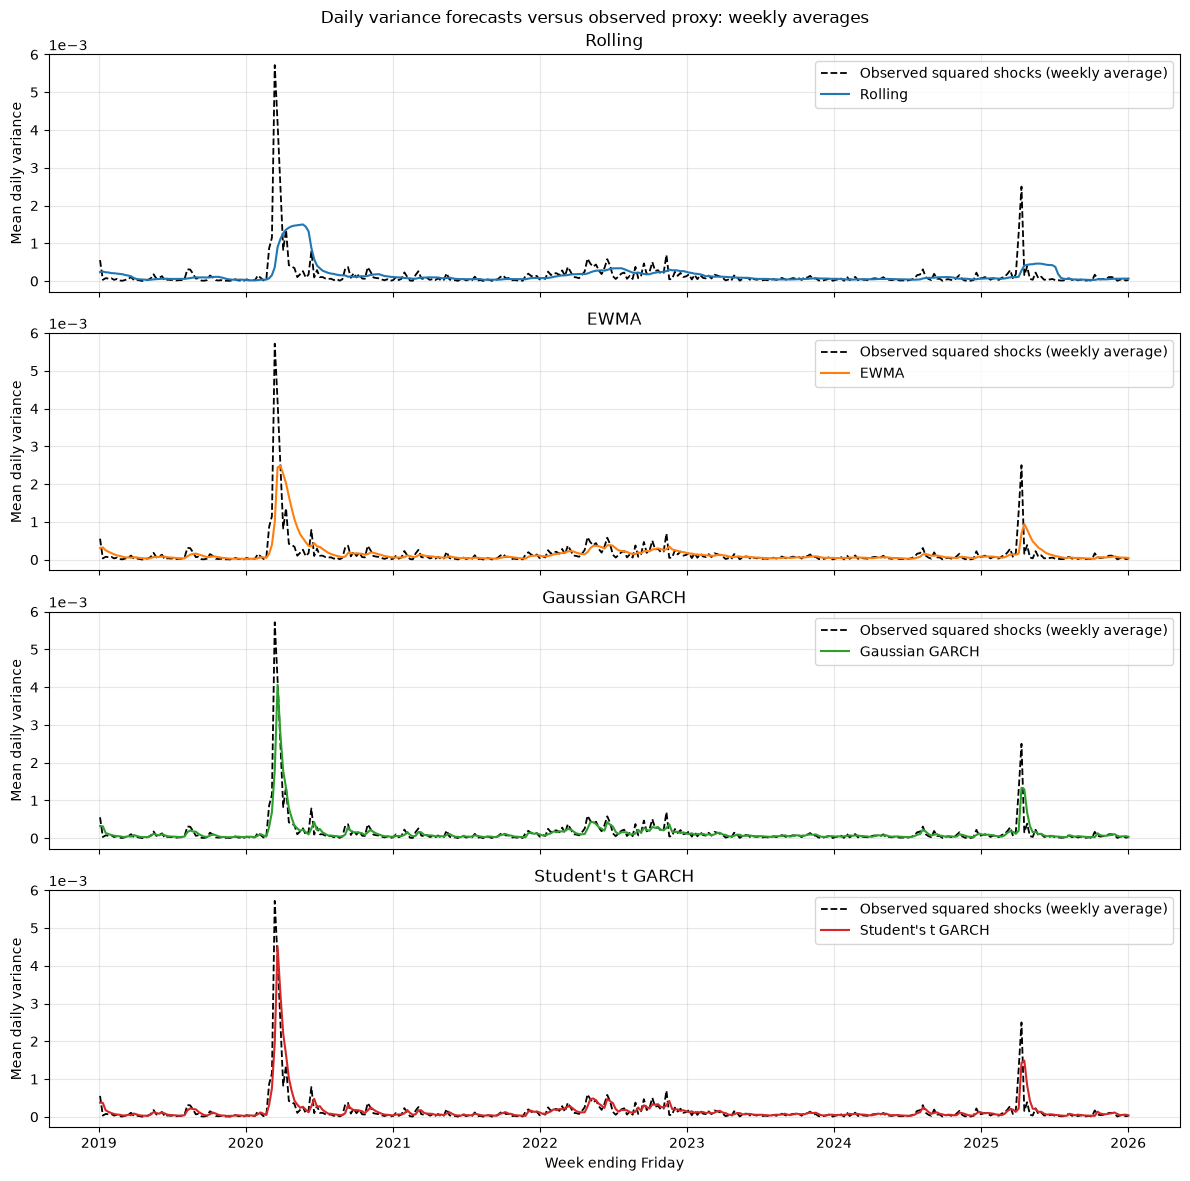

In [38]:
# Average forecasts and observed squared shocks over the same days each week.
comparison = test_forecasts.join(test_proxy.rename("Observed proxy"))
weekly_comparison = comparison.resample("W-FRI").mean()

fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True, sharey=True)

for ax, model, color in zip(axes, test_forecasts.columns, ["C0", "C1", "C2", "C3"]):
    ax.plot(weekly_comparison.index, weekly_comparison["Observed proxy"],
            color="black", linestyle="--", linewidth=1.3,
            label="Observed squared shocks (weekly average)")
    ax.plot(weekly_comparison.index, weekly_comparison[model],
            color=color, linewidth=1.5, label=model)
    ax.set_title(model)
    ax.set_ylabel("Mean daily variance")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Week ending Friday")
fig.suptitle("Daily variance forecasts versus observed proxy: weekly averages")
plt.tight_layout()
plt.show()


Gaussian GARCH(1,1) has the lowest QLIKE and MSE in this test sample.


**Why might GARCH outperform Rolling and EWMA models?**

Gaussian GARCH(1,1) achieves the lowest test-set QLIKE and MSE in our experiment. Its structure offers several plausible advantages:

- **Compared with rolling variance:** rolling variance weights observations equally within a fixed window and drops them abruptly when they leave it. GARCH updates variance recursively, allowing recent shocks to affect forecasts without a fixed cutoff.
- **Compared with EWMA:** EWMA uses one parameter, $\lambda$, tying the weight on new shocks to the weight on previous variance. GARCH estimates $\alpha$ and $\beta$ separately, providing more flexibility in balancing shock response and persistence.
- **Mean reversion:** with $\alpha+\beta<1$, GARCH's expected future variance returns toward $\bar h=\omega/(1-\alpha-\beta)$. Standard EWMA has no explicit long-run variance target. Mean reversion can help describe the gradual normalization of volatility after turbulent periods.
- **Compared with Student's $t$ GARCH(1,1):** Choosing Student's $t$ distribution in the GARCH model produces no improvement compared with the Gaussian distribution in our test sample. It is possible that a heavier-tailed distribution can improve the fit to returns without improving variance forecasts. Another possible explanation is that our evaluation measures variance accuracy, not tail accuracy. 


**Future directions.**

A direction for further investigation could be a careful comparison between Gaussian GARCH(1,1) and Student's $t$ GARCH(1,1). Another interesting direction would be to combine the GARCH volatility model with stock path and option pricing models. 


